### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom Function
from custom_function import *

In [5]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [6]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [7]:
food_price = food_price[['date', 'usdprice']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,0.563348
2009-01-01,0.452433
2010-01-01,0.505708
2011-01-01,0.546463
2012-01-01,0.467904


#### 2. Population Dataset

In [8]:
temp_population = get_dataset('\\Datasets\\population.csv')
temp_population.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,"Population, total",SP.POP.TOTL,54208.0,55434.0,56234.0,56699.0,57029.0,57357.0,...,102050.0,102565.0,103165.0,103776.0,104339.0,104865.0,105361.0,105846.0,106310.0,106766.0
1,Africa Eastern and Southern,AFE,"Population, total",SP.POP.TOTL,130836765.0,134159786.0,137614644.0,141202036.0,144920186.0,148769974.0,...,532760424.0,547482863.0,562601578.0,578075373.0,593871847.0,609978946.0,626392880.0,643090131.0,660046272.0,677243299.0
2,Afghanistan,AFG,"Population, total",SP.POP.TOTL,8996967.0,9169406.0,9351442.0,9543200.0,9744772.0,9956318.0,...,30117411.0,31161378.0,32269592.0,33370804.0,34413603.0,35383028.0,36296111.0,37171922.0,38041757.0,38928341.0
3,Africa Western and Central,AFW,"Population, total",SP.POP.TOTL,96396419.0,98407221.0,100506960.0,102691339.0,104953470.0,107289875.0,...,360285439.0,370243017.0,380437896.0,390882979.0,401586651.0,412551299.0,423769930.0,435229381.0,446911598.0,458803476.0
4,Angola,AGO,"Population, total",SP.POP.TOTL,5454938.0,5531451.0,5608499.0,5679409.0,5734995.0,5770573.0,...,24220660.0,25107925.0,26015786.0,26941773.0,27884380.0,28842482.0,29816769.0,30809787.0,31825299.0,32866268.0


In [9]:
temp_population = temp_population[temp_population['Country Code'] == 'MMR']
temp_population

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
160,Myanmar,MMR,"Population, total",SP.POP.TOTL,21736947.0,22211626.0,22697664.0,23198238.0,23717785.0,24259356.0,...,50990612.0,51413703.0,51852464.0,52280816.0,52680724.0,53045199.0,53382521.0,53708318.0,54045422.0,54409794.0


In [10]:
date = temp_population.columns
date = date[4:]
date

Index(['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object')

In [11]:
date.shape

(61,)

In [12]:
population_total = temp_population.copy()
population_total = population_total[date]
population_total = population_total.values
population_total

array([[21736947., 22211626., 22697664., 23198238., 23717785., 24259356.,
        24823937., 25410054., 26015239., 26635852., 27269063., 27913749.,
        28570093., 29238168., 29918469., 30611093., 31314347., 32026748.,
        32748782., 33481397., 34224316., 34976465., 35734273., 36491804.,
        37241530., 37977087., 38698484., 39404350., 40085653., 40731439.,
        41335188., 41890192., 42401686., 42889992., 43383421., 43901598.,
        44452203., 45027223., 45611220., 46181075., 46719698., 47225119.,
        47702163., 48148907., 48564489., 48949931., 49301049., 49621479.,
        49929642., 50250366., 50600827., 50990612., 51413703., 51852464.,
        52280816., 52680724., 53045199., 53382521., 53708318., 54045422.,
        54409794.]])

In [13]:
date = pd.to_datetime(date, format='%Y')

In [14]:
population_total = population_total[0]
population_total.shape

(61,)

In [15]:
population = pd.DataFrame()
population['population_total'] = population_total
population

,population_total
0,21736947.0
1,22211626.0
2,22697664.0
3,23198238.0
4,23717785.0
...,...
56,53045199.0
57,53382521.0
58,53708318.0
59,54045422.0


##### Filling data with linear interpolation

In [16]:
population = population.interpolate(method='linear')
population

,population_total
0,21736947.0
1,22211626.0
2,22697664.0
3,23198238.0
4,23717785.0
...,...
56,53045199.0
57,53382521.0
58,53708318.0
59,54045422.0


In [17]:
population['date']=date
population = population.set_index('date')
population.columns=['population_total']
population.head()

,population_total
date,
1960-01-01,21736947.0
1961-01-01,22211626.0
1962-01-01,22697664.0
1963-01-01,23198238.0
1964-01-01,23717785.0


### Merge Population and Food Price

In [18]:
food_price_population = food_price.join(population, how='inner')
food_price_population

,food_price,population_total
date,,
2008-01-01,0.563348,49929642.0
2009-01-01,0.452433,50250366.0
2010-01-01,0.505708,50600827.0
2011-01-01,0.546463,50990612.0
2012-01-01,0.467904,51413703.0
2013-01-01,0.513739,51852464.0
2014-01-01,0.918071,52280816.0
2015-01-01,1.059368,52680724.0
2016-01-01,1.182692,53045199.0


### Correlation

In [19]:
correlation=food_price_population['food_price'].corr(food_price_population['population_total'])
correlation

0.7603977355889194

### Make scatter plot

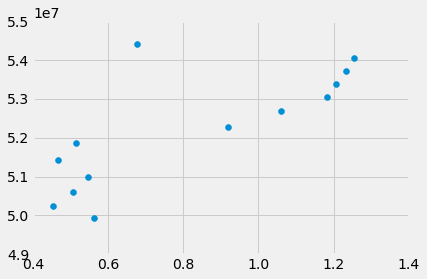

In [20]:
plt.scatter(food_price_population['food_price'],food_price_population['population_total'])
plt.show()

### Normalization

In [21]:
date = food_price_population.index

In [22]:
scaler = MinMaxScaler()

In [23]:
food_price_population = scaler.fit_transform(food_price_population)
food_price_population = pd.DataFrame(food_price_population)
food_price_population['date'] = date
food_price_population.set_index('date', inplace=True)
food_price_population.columns = ['food_price', 'population_total']
food_price_population.head()

,food_price,population_total
date,,
2008-01-01,0.138512,0.000000
2009-01-01,0.000000,0.071588
2010-01-01,0.066530,0.149813
2011-01-01,0.117426,0.236816
2012-01-01,0.019321,0.331252


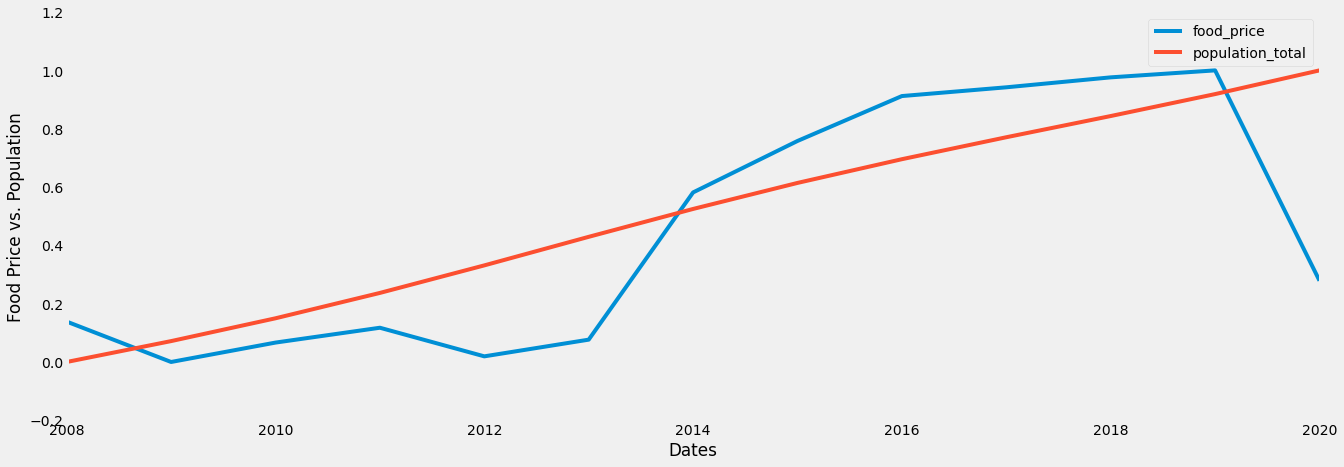

In [24]:
line_ax = food_price_population.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. Population')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is positive relation between Food Price and Population</span>